# Dose test: JJ resistance map

Probes a dose test device by device and saves each reading by **block, row, column**. Needs `K2450.py` and `dosetest_tools.py` in this folder. Readings are ±13 mV I-V sweeps, so nothing is tuned.

**Workflow**
1. Set the layout in **Settings**, then run **Settings**, **Connect** and **Start**.
2. Land on the device that `here()` shows, then run `m()`. It measures, saves, and moves to the next device.
3. Repeat `m()` for every device. Use `skip()` for a missing or damaged device, `redo()` to measure the previous one again, and `goto("B1", 3, 7)` to jump.

Every reading is written to the CSV straight away. If the kernel restarts, rerun Settings, Connect and Start, and it carries on from the first unmeasured device.

## Settings

In [ ]:
from pathlib import Path
from K2450 import K2450
from dosetest_tools import *

In [ ]:
RESOURCE  = "TCPIP0::192.168.50.2::inst0::INSTR"
TERMINALS = "REAR"
FOUR_WIRE = False
DATA_DIR  = Path(r"C:\Users\hatlab\Probing_Data\Israa")
SAMPLE    = "112026_D2_DT_MAN45_30Torr_20min"

In [64]:
# ---- layout ----
BLOCKS = ["B1"]   # block names, in the order you'll probe them
N_ROWS = int(input("Rows per block: "))       # row 1, col 1 = first device
N_COLS = int(input("Columns per block: "))
ORDER  = "raster"                    # down each column, columns left to right.
                                    # "snake": every other column goes back up; "raster": always top to bottom


In [ ]:
DOSES = None      # optional: {("B1", row, col): dose, ...}; leave None if not needed

R_SHORT = 1000    # Ohm: below this, flagged SHORT
R_OPEN  = 1e6      # Ohm: above this (or negative), flagged OPEN
SHOW_IV = True     # plot the I-V after every m()
SHOW_GRID = True   # show the block's grid after every m()

## Connect

In [157]:
try:
    smu.close()
except Exception:
    pass

smu = K2450(RESOURCE, terminals=TERMINALS, four_wire=FOUR_WIRE)
smu.configure(ilim=1e-4)   # 100 uA: ample for a 13 mV readout, limits a short
smu.set_v(0.0)
smu.output(True)
print("Terminals:", smu.q(":ROUT:TERM?"), "  Output ON at 0 V")

KEITHLEY INSTRUMENTS,MODEL 2450,MYFP002618,1.7.16a
Terminals: REAR   Output ON at 0 V


## Start

In [ ]:
setup(smu, SAMPLE, DATA_DIR, BLOCKS, N_ROWS, N_COLS, order=ORDER,
      r_short=R_SHORT, r_open=R_OPEN, show_iv=SHOW_IV, show_grid=SHOW_GRID, doses=DOSES)

### for debugging:

In [173]:
# # smu.set_v(0.0)
# smu.w(":ABOR")
# print("Output:    ", smu.q(":OUTP?"))
# print("Set V:     ", smu.q(":SOUR:VOLT?"))
# print("Range:     ", smu.q(":SOUR:VOLT:RANG?"))
# v, i = smu.read()          # takes a fresh measurement
# print(f"Measured:   V = {v * 1e3:.4f} mV,  I = {i * 1e9:.2f} nA")
# print("Errors:    ", smu.check_errors())

## Probe
Land on the device shown, run this cell, repeat.

B1 r10 c8: R = 1059.5 Ohm  (fit nan %)
Next: block B1, row 1, col 9   (81/100)


c:\Users\hatlab\msmt-env\JJ_probing\K2450.py:200: RankWarning: Polyfit may be poorly conditioned
  slope, icpt = np.polyfit(d.V, d.I, 1)
C:\Users\hatlab\AppData\Local\Temp\ipykernel_7260\1473029645.py:48: RankWarning: Polyfit may be poorly conditioned
  slope, icpt = np.polyfit(iv.V, iv.I, 1)


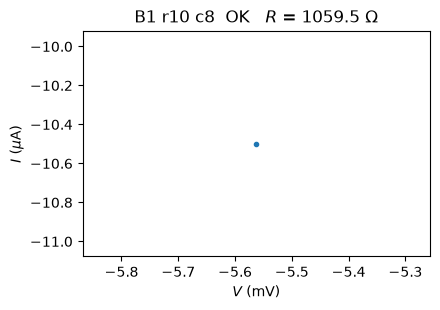

col,1,2,3,4,5,6,7,8,9,10
row,,,,,,,,,,
1,24952,15768,11034,8092,6420,5011,4169,1518,,
2,24938,15775,11355,8187,6300,4996,4146,1518,,
3,24461,15550,11253,8189,6426,5014,4178,1676,,
4,25152,15980,11082,8071,6201,4998,4103,1752,,
5,24752,15708,11047,8093,6252,4948,4055,1159,,
6,23700,15671,11008,8015,6102,4817,4064,1113,,
7,23616,15119,10928,8053,6160,4905,4033,1192,,
8,23570,15299,10567,7770,6241,4976,4131,1120,,
9,23288,15317,10680,7985,6207,4871,1438,1054,,


In [167]:
m()
# redo()
# skip()
# goto("B1",3,8)

In [12]:
d = smu.last_iv
print(f"per point: {d.t.diff().median() * 1e3:.0f} ms,  "
      f"whole sweep: {d.t.iloc[-1] - d.t.iloc[0]:.2f} s")

per point: 92 ms,  whole sweep: 3.85 s


## Grid so far
Shows the current block; `show_grid("B2")` for another. It also appears after every `m()`.

In [168]:
show_grid()

col,1,2,3,4,5,6,7,8,9,10
row,,,,,,,,,,
1,24952,15768,11034,8092,6420,5011,4169,1518,,
2,24938,15775,11355,8187,6300,4996,4146,1518,,
3,24461,15550,11253,8189,6426,5014,4178,1676,,
4,25152,15980,11082,8071,6201,4998,4103,1752,,
5,24752,15708,11047,8093,6252,4948,4055,1159,,
6,23700,15671,11008,8015,6102,4817,4064,1113,,
7,23616,15119,10928,8053,6160,4905,4033,1192,,
8,23570,15299,10567,7770,6241,4976,4131,1120,,
9,23288,15317,10680,7985,6207,4871,1438,1054,,


## Look at one device's I-V
`all_reps=True` overlays every reading of that device, e.g. after re-landing.

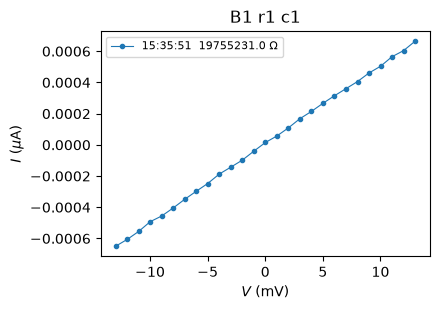

In [6]:
show_iv("B1", 1, 1)

## Look at a block
Red letters: `S` = short, `O` = open, `X` = skipped.

In [172]:
grid("B1").round(0)

col,1,2,3,4,5,6,7,8,9,10
row,,,,,,,,,,
1,24952.0,15768.0,11034.0,8092.0,6420.0,5011.0,4169.0,1518.0,NaN,NaN
2,24938.0,15775.0,11355.0,8187.0,6300.0,4996.0,4146.0,1518.0,NaN,NaN
3,24461.0,15550.0,11253.0,8189.0,6426.0,5014.0,4178.0,1676.0,NaN,NaN
4,25152.0,15980.0,11082.0,8071.0,6201.0,4998.0,4103.0,1752.0,NaN,NaN
5,24752.0,15708.0,11047.0,8093.0,6252.0,4948.0,4055.0,1159.0,NaN,NaN
6,23700.0,15671.0,11008.0,8015.0,6102.0,4817.0,4064.0,1113.0,NaN,NaN
7,23616.0,15119.0,10928.0,8053.0,6160.0,4905.0,4033.0,1192.0,NaN,NaN
8,23570.0,15299.0,10567.0,7770.0,6241.0,4976.0,4131.0,1120.0,NaN,NaN
9,23288.0,15317.0,10680.0,7985.0,6207.0,4871.0,1438.0,1054.0,NaN,NaN


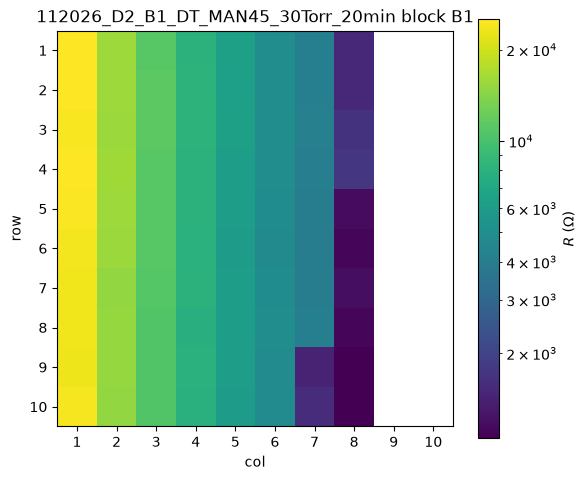

In [169]:
plot("B1")

## Export
Writes one CSV per block laid out like the chip, plus a ddh5 of everything.

In [170]:
export()

ddh5 written


## Shut down

In [171]:
smu.close()   # 0 V, output off